# Task 2 — Indic Speech Recognition and Speech-to-Answer Prototype

**Please run this notebook in Google Colab.** It builds a reproducible baseline, evaluates it on 100 public Hindi/Kannada speech examples, compares automatic language detection with language-constrained decoding, and exports the results. An optional final section provides a speech-to-answer demo.

**Important research note:** FLEURS is primarily read speech, so the benchmark measures ASR on clean read utterances; it does not, by itself, prove interruption handling or full-duplex turn-taking. The decoding comparison is a measurable ASR ablation. The proposed latency-aware turn controller is also implemented and unit-tested as a policy prototype, but those tests are synthetic—not evidence of real conversational turn-taking performance. We will report actual numbers produced by the run, including if the ASR change does not help.

**Before running:** In Colab, select **Runtime → Change runtime type → T4 GPU** (or another GPU). If you cannot access a GPU, the notebook still has a CPU fallback, but evaluation will be slower.

Dataset: [Google FLEURS](https://huggingface.co/datasets/google/fleurs) — Hindi (`hi_in`) and Kannada (`kn_in`), test split. Speech-recognition model: [OpenAI Whisper-small](https://huggingface.co/openai/whisper-small).

## 1. Install required packages

In [52]:
%pip -q install "transformers>=4.45,<5" "datasets>=3.2,<4" "jiwer>=3.0,<5" accelerate soundfile "pandas>=2.2,<2.3" matplotlib

## 2. Configuration and environment check

This runs 50 Hindi and 50 Kannada examples (100 total).

In [ ]:
import os, re, time, json, random, gc, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset, Audio
from transformers import pipeline
from jiwer import wer, cer
from IPython.display import display

SEED = 42
N_PER_LANGUAGE = 50

# General multilingual baseline
MODEL_ID = "openai/whisper-small"

# Use a new output folder so old and new results do not mix.
OUTPUT_DIR = Path("/content/task2_results_specialist")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

LANGUAGES = {
    "hi_in": {
        "name": "Hindi",
        "whisper_language": "hindi",
        "whisper_code": "hi",
        "specialist_model": "vasista22/whisper-hindi-large-v2",
    },
    "kn_in": {
        "name": "Kannada",
        "whisper_language": "kannada",
        "whisper_code": "kn",
        "specialist_model": "vasista22/whisper-kannada-medium",
    },
}

DEVICE = 0 if torch.cuda.is_available() else -1
TORCH_DTYPE = (
    torch.float16 if torch.cuda.is_available()
    else torch.float32
)

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected; inference will be slower.")

print("Baseline model:", MODEL_ID)
print("Planned examples:", N_PER_LANGUAGE * len(LANGUAGES))

PyTorch: 2.11.0+cu130
Pandas: 3.1.0
GPU available: True
GPU: Tesla T4
Baseline model: openai/whisper-small
Planned examples: 100


## 3. Load the test set

The reference transcription comes from the dataset.

In [ ]:
samples = []

for config, info in LANGUAGES.items():
    print(f"Loading FLEURS: {info['name']} ({config})")

    ds = load_dataset(
        "google/fleurs",
        config,
        split="test"
    )

    ds = ds.cast_column("audio", Audio(sampling_rate=16000))

    if len(ds) < N_PER_LANGUAGE:
        raise ValueError(
            f"Not enough examples for {config}: {len(ds)}"
        )

    ds = ds.shuffle(seed=SEED).select(range(N_PER_LANGUAGE))

    for local_idx, row in enumerate(ds):
        reference = (
            row.get("transcription")
            or row.get("raw_transcription")
            or ""
        )

        audio_item = row["audio"]
        audio_array = np.asarray(
            audio_item["array"], dtype=np.float32
        )

        if audio_array.ndim != 1:
            audio_array = np.mean(
                audio_array, axis=0
            ).astype(np.float32)

        samples.append({
            "sample_id": f"{config}_{local_idx:03d}",
            "language_code": config,
            "language": info["name"],
            "whisper_language": info["whisper_language"],
            "whisper_code": info["whisper_code"],
            "specialist_model": info["specialist_model"],
            "reference": str(reference).strip(),
            "audio_array": audio_array,
            "sampling_rate": int(audio_item["sampling_rate"]),
        })

if len({s["sample_id"] for s in samples}) != len(samples):
    raise ValueError("Duplicate sample IDs detected.")

if any(not s["reference"] for s in samples):
    raise ValueError("An example has an empty reference transcript.")

print(f"Loaded {len(samples)} examples.")
print(pd.Series([s["language"] for s in samples]).value_counts())
print("Unique IDs:", len(set(s["sample_id"] for s in samples)))
print("Example reference:", samples[0]["reference"])

Loading FLEURS: Hindi (hi_in)
Loading FLEURS: Kannada (kn_in)
Loaded 100 examples.
Hindi      50
Kannada    50
Name: count, dtype: int64
Unique IDs: 100
Example reference: ऐसा माना जाता है कि पेरिस के निवासी अहंकारी असभ्य और अभिमानी होते हैं


## 4. Load Whisper and warm it up

Baseline = let Whisper detect the language automatically. Improved condition = provide the known language label, so decoding does not need to infer the language from the audio.

In [ ]:
asr = pipeline(
    task="automatic-speech-recognition",
    model=MODEL_ID,
    device=DEVICE,
    torch_dtype=TORCH_DTYPE,
)

def set_whisper_language(asr_pipe, lang_code):
    prompt_ids = asr_pipe.tokenizer.get_decoder_prompt_ids(
        language=lang_code,
        task="transcribe"
    )

    asr_pipe.model.config.forced_decoder_ids = prompt_ids
    asr_pipe.model.generation_config.forced_decoder_ids = prompt_ids


def audio_payload(sample):
    # Create a fresh audio dictionary for every call.
    return {
        "raw": np.asarray(
            sample["audio_array"], dtype=np.float32
        ).copy(),
        "sampling_rate": int(sample["sampling_rate"]),
    }


def sync_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


set_whisper_language(asr, samples[0]["whisper_code"])

_ = asr(
    audio_payload(samples[0]),
    generate_kwargs={"task": "transcribe"},
)

print("Baseline model loaded and warmed up.")

Device set to use cuda:0


Baseline model loaded and warmed up.


## 5. Run baseline and improved transcription

Both conditions use the same model, test audio, and hardware. Only the language-decoding hint changes. The cell writes a checkpoint CSV periodically, so some progress is saved if Colab certainly disconnects.

In [ ]:
RESULTS_PATH = OUTPUT_DIR / "task2_asr_results.csv"
BASELINE_CACHE = OUTPUT_DIR / "baseline_transcriptions.csv"

# ==========================================
# A. Reuse or run the baseline transcription
# ==========================================
expected_ids = {str(s["sample_id"]) for s in samples}
baseline_df = None

if BASELINE_CACHE.exists():
    cached = pd.read_csv(BASELINE_CACHE)
    if (
        len(cached) == len(samples)
        and set(cached["sample_id"].astype(str)) == expected_ids
        and {"baseline_transcript", "baseline_latency_s",
             "baseline_rtf", "audio_duration_s"}.issubset(cached.columns)
    ):
        baseline_df = cached
        print("✅ Reusing all 100 saved baseline results.")

if baseline_df is None:
    print("Running baseline Whisper-small...")

    asr = pipeline(
        "automatic-speech-recognition",
        model=MODEL_ID,
        device=DEVICE,
        torch_dtype=TORCH_DTYPE,
    )

    baseline_records = []

    for i, s in enumerate(samples, start=1):
        set_whisper_language(asr, s["whisper_code"])
        duration_s = len(s["audio_array"]) / s["sampling_rate"]

        sync_device()
        t0 = time.perf_counter()
        output = asr(
            audio_payload(s),
            generate_kwargs={"task": "transcribe"},
        )
        sync_device()
        elapsed = time.perf_counter() - t0

        baseline_records.append({
            "sample_id": s["sample_id"],
            "baseline_transcript": str(output.get("text", "")).strip(),
            "audio_duration_s": duration_s,
            "baseline_latency_s": elapsed,
            "baseline_rtf": elapsed / max(duration_s, 1e-9),
        })

        if i % 10 == 0 or i == len(samples):
            pd.DataFrame(baseline_records).to_csv(
                BASELINE_CACHE, index=False
            )
            print(f"Baseline: {i}/{len(samples)}")

    baseline_df = pd.DataFrame(baseline_records)

# Release any existing baseline model before loading specialists.
if "asr" in globals():
    del asr

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ==========================================
# B. Evaluate language-specialized models
# ==========================================
specialist_records = []

for config, info in LANGUAGES.items():
    subset = [s for s in samples if s["language_code"] == config]
    model_id = info["specialist_model"]

    print(f"\nLoading {info['name']} specialist model:")
    print(model_id)

    specialist_asr = pipeline(
        "automatic-speech-recognition",
        model=model_id,
        device=DEVICE,
        torch_dtype=TORCH_DTYPE,
    )

    set_whisper_language(specialist_asr, info["whisper_code"])

    # Warm-up: do not include its time in the reported latency.
    # Do not pass task="transcribe" to these older specialist models.
    _ = specialist_asr(audio_payload(subset[0]))

    for j, s in enumerate(subset, start=1):
        duration_s = len(s["audio_array"]) / s["sampling_rate"]

        sync_device()
        t0 = time.perf_counter()
        output = specialist_asr(audio_payload(s))
        sync_device()
        elapsed = time.perf_counter() - t0

        specialist_records.append({
            "sample_id": s["sample_id"],
            "improved_transcript": str(
                output.get("text", "")
            ).strip(),
            "improved_latency_s": elapsed,
            "improved_rtf": elapsed / max(duration_s, 1e-9),
            "improved_model": model_id,
        })

        if j % 10 == 0 or j == len(subset):
            pd.DataFrame(specialist_records).to_csv(
                OUTPUT_DIR / "specialist_checkpoint.csv",
                index=False,
            )
            print(f"{info['name']}: {j}/{len(subset)} completed")

    del specialist_asr
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ==========================================
# C. Verify and merge fresh results
# ==========================================
specialist_df = pd.DataFrame(specialist_records)

if len(baseline_df) != len(samples):
    raise RuntimeError("Baseline result count does not match samples.")

if len(specialist_df) != len(samples):
    raise RuntimeError(
        f"Specialist result count is {len(specialist_df)}, "
        f"but expected {len(samples)}. Do not calculate metrics yet."
    )

metadata_df = pd.DataFrame([
    {
        "sample_id": s["sample_id"],
        "language": s["language"],
        "language_code": s["language_code"],
        "reference": s["reference"],
    }
    for s in samples
])

results_df = (
    metadata_df
    .merge(baseline_df, on="sample_id", validate="one_to_one")
    .merge(specialist_df, on="sample_id", validate="one_to_one")
)

if len(results_df) != len(samples):
    raise RuntimeError("Merged results are incomplete.")

results_df.to_csv(RESULTS_PATH, index=False)

print("\n✅ Both conditions completed.")
print("Examples:", len(results_df))
print("Results saved to:", RESULTS_PATH)

display(results_df[
    [
        "sample_id",
        "language",
        "baseline_transcript",
        "improved_transcript",
        "reference",
    ]
].head(10))


# ==========================================
# D. Restore baseline model for the optional demo
# ==========================================
print("\nReloading baseline model for the optional demo...")

asr = pipeline(
    "automatic-speech-recognition",
    model=MODEL_ID,
    device=DEVICE,
    torch_dtype=TORCH_DTYPE,
)

print("✅ Ready for the metrics and plotting cells.")

✅ Reusing all 100 saved baseline results.

Loading Hindi specialist model:
vasista22/whisper-hindi-large-v2


Device set to use cuda:0
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.


Hindi: 10/50 completed
Hindi: 20/50 completed
Hindi: 30/50 completed
Hindi: 40/50 completed
Hindi: 50/50 completed

Loading Kannada specialist model:
vasista22/whisper-kannada-medium


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/3.06G [00:00<?, ?B/s]

...

Kannada: 10/50 completed
Kannada: 20/50 completed
Kannada: 30/50 completed
Kannada: 40/50 completed
Kannada: 50/50 completed

✅ Both conditions completed.
Examples: 100
Results saved to: /content/task2_results_specialist/task2_asr_results.csv


,sample_id,language,baseline_transcript,improved_transcript,reference
0,hi_in_000,Hindi,ایسا مانا جاتا ہے کہ پیریس کی نواسی اہنکاری اص...,"ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ...",ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...
1,hi_in_001,Hindi,"कुछ आँगो में आज्टर केंद्रक होता है, जिस का मतल...","कुछ अड़वों में अस्थिर केंद्रक होता है, जिसका म...",कुछ अणुओं में अस्थिर केंद्रक होता है जिसका मतल...
2,hi_in_002,Hindi,हला की शेंगें जों इस मामले में कुछ हद्टक एक दे...,हालाँकि सिंगेन जॉन इस मामले में कुछ हद तक एक द...,हालांकि शेंगेन ज़ोन इस मामले में कुछ हद तक एक ...
3,hi_in_003,Hindi,"चनिन्दा रूट पर बड़ी कमपनियो के खुटके मिमान है,...",जनहिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...,चुनिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...
4,hi_in_004,Hindi,असी कोई वेश्विक परीबाशा नहीं चिसके लिए निर्मित...,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...
5,hi_in_005,Hindi,"एसा माना जाता है की पैरिस के निवासी, अहांकारी,...","ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ...",ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...
6,hi_in_006,Hindi,मद्दे पुर्व की गर मजल्वायु में गर उतना जरूरी न...,मध्य-पूर्व की गर्म जलवायु में घर उतना ज़रूरी न...,मध्यपूर्व की गर्म जलवायु में घर उतना ज़रूरी नह...
7,hi_in_007,Hindi,आपसी सहयों करते हुए समाज में रहते है और मिलकर ...,"ऐसी संस्कृति को सभ्यता कहते हैं, जो लोगों के ए...",ऐसी संस्कृति को सभ्यता कहते हैं जो लोगों के एक...
8,hi_in_008,Hindi,वायल्ट कार्ट करीट लेना पाएदेमन भी हो सकता है क...,वाइल्ड कार्ड खरीदना फायदेमंद भी हो सकता है क्य...,वाइल्ड कार्ड खरीद लेना फ़ायदेमंद भी हो सकता है...
9,hi_in_009,Hindi,"अश्पताल से सक्रम्म, नियंट्रन्ट करने के लिए, नि...",अस्पताल से संक्रमण नियंत्रण करने के लिए नियमों...,अस्पताल ने संक्रमण नियंत्रण के लिए नियमों का प...



Reloading baseline model for the optional demo...


Device set to use cuda:0


✅ Ready for the metrics and plotting cells.


In [ ]:
#recompute baseline and reuse specialist results

BASELINE_V2 = OUTPUT_DIR / "baseline_transcriptions_prompted_v2.csv"
SPECIALIST_CACHE = OUTPUT_DIR / "specialist_checkpoint.csv"

baseline_records = []

print("Recomputing the baseline with explicit language prompts...")

for i, s in enumerate(samples, start=1):
    set_whisper_language(asr, s["whisper_code"])

    duration_s = len(s["audio_array"]) / s["sampling_rate"]

    sync_device()
    t0 = time.perf_counter()

    output = asr(
        audio_payload(s),
        generate_kwargs={"task": "transcribe"},
    )

    sync_device()
    elapsed = time.perf_counter() - t0

    baseline_records.append({
        "sample_id": s["sample_id"],
        "baseline_transcript": str(output.get("text", "")).strip(),
        "audio_duration_s": duration_s,
        "baseline_latency_s": elapsed,
        "baseline_rtf": elapsed / max(duration_s, 1e-9),
    })

    if i % 10 == 0 or i == len(samples):
        pd.DataFrame(baseline_records).to_csv(
            BASELINE_V2, index=False
        )
        print(f"Baseline completed: {i}/{len(samples)}")

baseline_df = pd.DataFrame(baseline_records)

# Reuse the completed specialist-model predictions
if not SPECIALIST_CACHE.exists():
    raise FileNotFoundError(
        "Specialist results not found. Please rerun the specialist evaluation."
    )

specialist_df = pd.read_csv(SPECIALIST_CACHE)

expected_ids = {str(s["sample_id"]) for s in samples}

if (
    len(baseline_df) != len(samples)
    or set(baseline_df["sample_id"].astype(str)) != expected_ids
):
    raise RuntimeError("Baseline results are incomplete or duplicated.")

if (
    len(specialist_df) != len(samples)
    or set(specialist_df["sample_id"].astype(str)) != expected_ids
    or specialist_df["sample_id"].astype(str).duplicated().any()
):
    raise RuntimeError("Specialist results are incomplete or duplicated.")

metadata_df = pd.DataFrame([
    {
        "sample_id": s["sample_id"],
        "language": s["language"],
        "language_code": s["language_code"],
        "reference": s["reference"],
    }
    for s in samples
])

results_df = (
    metadata_df
    .merge(baseline_df, on="sample_id", validate="one_to_one")
    .merge(specialist_df, on="sample_id", validate="one_to_one")
)

RESULTS_PATH = OUTPUT_DIR / "task2_asr_results.csv"
results_df.to_csv(RESULTS_PATH, index=False)

print("\n✅ Fresh baseline and saved specialist results combined.")
print("Total examples:", len(results_df))
print("Saved to:", RESULTS_PATH)

display(results_df[
    [
        "sample_id",
        "language",
        "reference",
        "baseline_transcript",
        "improved_transcript",
    ]
].head(10))

Recomputing the baseline with explicit language prompts...
Baseline completed: 10/100
Baseline completed: 20/100
Baseline completed: 30/100
Baseline completed: 40/100
Baseline completed: 50/100
Baseline completed: 60/100
Baseline completed: 70/100
Baseline completed: 80/100
Baseline completed: 90/100
Baseline completed: 100/100

✅ Fresh baseline and saved specialist results combined.
Total examples: 100
Saved to: /content/task2_results_specialist/task2_asr_results.csv


,sample_id,language,reference,baseline_transcript,improved_transcript
0,hi_in_000,Hindi,ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...,ایسا مانا جاتا ہے کہ پیریس کی نواسی اہنکاری اص...,"ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ..."
1,hi_in_001,Hindi,कुछ अणुओं में अस्थिर केंद्रक होता है जिसका मतल...,"कुछ आँगो में आज्टर केंद्रक होता है, जिस का मतल...","कुछ अड़वों में अस्थिर केंद्रक होता है, जिसका म..."
2,hi_in_002,Hindi,हालांकि शेंगेन ज़ोन इस मामले में कुछ हद तक एक ...,हला की शेंगें जों इस मामले में कुछ हद्टक एक दे...,हालाँकि सिंगेन जॉन इस मामले में कुछ हद तक एक द...
3,hi_in_003,Hindi,चुनिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...,"चनिन्दा रूट पर बड़ी कमपनियो के खुटके मिमान है,...",जनहिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...
4,hi_in_004,Hindi,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...,असी कोई वेश्विक परीबाशा नहीं चिसके लिए निर्मित...,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...
5,hi_in_005,Hindi,ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...,"एसा माना जाता है की पैरिस के निवासी, अहांकारी,...","ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ..."
6,hi_in_006,Hindi,मध्यपूर्व की गर्म जलवायु में घर उतना ज़रूरी नह...,मद्दे पुर्व की गर मजल्वायु में गर उतना जरूरी न...,मध्य-पूर्व की गर्म जलवायु में घर उतना ज़रूरी न...
7,hi_in_007,Hindi,ऐसी संस्कृति को सभ्यता कहते हैं जो लोगों के एक...,आपसी सहयों करते हुए समाज में रहते है और मिलकर ...,"ऐसी संस्कृति को सभ्यता कहते हैं, जो लोगों के ए..."
8,hi_in_008,Hindi,वाइल्ड कार्ड खरीद लेना फ़ायदेमंद भी हो सकता है...,वायल्ट कार्ट करीट लेना पाएदेमन भी हो सकता है क...,वाइल्ड कार्ड खरीदना फायदेमंद भी हो सकता है क्य...
9,hi_in_009,Hindi,अस्पताल ने संक्रमण नियंत्रण के लिए नियमों का प...,"अश्पताल से सक्रम्म, नियंट्रन्ट करने के लिए, नि...",अस्पताल से संक्रमण नियंत्रण करने के लिए नियमों...


## 6. Calculate WER, CER, latency and real-time factor

Lower WER/CER is better. Latency is the time for one ASR inference, excluding model download/loading. RTF below 1.0 means processing took less time than the duration of the audio.

In [ ]:
def normalize_text(text):
    text = str(text or "").lower()
    # Remove punctuation while retaining Unicode letters/digits and whitespace.
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()

def safe_wer(refs, hyps):
    refs = [normalize_text(x) for x in refs]
    hyps = [normalize_text(x) for x in hyps]
    return float(wer(refs, hyps))

def safe_cer(refs, hyps):
    refs = [normalize_text(x) for x in refs]
    hyps = [normalize_text(x) for x in hyps]
    return float(cer(refs, hyps))

metric_rows = []
for language in ["Hindi", "Kannada", "OVERALL"]:
    group = results_df if language == "OVERALL" else results_df[results_df["language"] == language]
    for condition, pred_col, latency_col, rtf_col in [
        ("Baseline: language-prompted Whisper-small", "baseline_transcript", "baseline_latency_s", "baseline_rtf"),
        ("Improved: language-specialized Whisper", "improved_transcript", "improved_latency_s", "improved_rtf"),
    ]:
        metric_rows.append({
            "language": language,
            "condition": condition,
            "examples": len(group),
            "WER": safe_wer(group["reference"].tolist(), group[pred_col].tolist()),
            "CER": safe_cer(group["reference"].tolist(), group[pred_col].tolist()),
            "mean_latency_s": float(group[latency_col].mean()),
            "p95_latency_s": float(group[latency_col].quantile(0.95)),
            "mean_RTF": float(group[rtf_col].mean()),
        })

metrics_df = pd.DataFrame(metric_rows)
metrics_df = metrics_df.round({"WER": 4, "CER": 4, "mean_latency_s": 3, "p95_latency_s": 3, "mean_RTF": 3})
METRICS_PATH = OUTPUT_DIR / "task2_metrics_summary.csv"
metrics_df.to_csv(METRICS_PATH, index=False)
display(metrics_df)
print("Saved metrics:", METRICS_PATH)

,language,condition,examples,WER,CER,mean_latency_s,p95_latency_s,mean_RTF
0,Hindi,Baseline: language-prompted Whisper-small,50,0.5298,0.3603,2.502,6.484,0.241
1,Hindi,Improved: language-specialized Whisper,50,0.0396,0.0199,21.070,41.037,1.965
2,Kannada,Baseline: language-prompted Whisper-small,50,2.0571,1.3348,7.630,8.521,0.689
3,Kannada,Improved: language-specialized Whisper,50,0.0662,0.0371,23.072,45.192,1.860
4,OVERALL,Baseline: language-prompted Whisper-small,100,1.3398,0.8852,5.066,8.506,0.465
5,OVERALL,Improved: language-specialized Whisper,100,0.0537,0.0292,22.071,41.847,1.912


Saved metrics: /content/task2_results_specialist/task2_metrics_summary.csv


## 7. Inspect changed examples and errors

In [ ]:
def _norm_for_compare(x):
    return normalize_text(x)

changed = results_df[
    results_df.apply(lambda r: _norm_for_compare(r["baseline_transcript"]) != _norm_for_compare(r["improved_transcript"]), axis=1)
].copy()
print(f"Transcripts changed by model choice: {len(changed)}/{len(results_df)}")
display(changed[["sample_id", "language", "reference", "baseline_transcript", "improved_transcript"]].head(15))

# Inspect the highest baseline-WER examples to find common failure patterns.
def _sample_wer(row):
    return wer(normalize_text(row["reference"]), normalize_text(row["baseline_transcript"]))

results_df["baseline_sample_wer"] = results_df.apply(_sample_wer, axis=1)
print("Examples with highest baseline errors:")
display(results_df.sort_values("baseline_sample_wer", ascending=False)[
    ["sample_id", "language", "reference", "baseline_transcript", "improved_transcript", "baseline_sample_wer"]
].head(10))
results_df.drop(columns=["baseline_sample_wer"]).to_csv(RESULTS_PATH, index=False)

Transcripts changed by model choice: 100/100


,sample_id,language,reference,baseline_transcript,improved_transcript
0,hi_in_000,Hindi,ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...,ایسا مانا جاتا ہے کہ پیریس کی نواسی اہنکاری اص...,"ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ..."
1,hi_in_001,Hindi,कुछ अणुओं में अस्थिर केंद्रक होता है जिसका मतल...,"कुछ आँगो में आज्टर केंद्रक होता है, जिस का मतल...","कुछ अड़वों में अस्थिर केंद्रक होता है, जिसका म..."
2,hi_in_002,Hindi,हालांकि शेंगेन ज़ोन इस मामले में कुछ हद तक एक ...,हला की शेंगें जों इस मामले में कुछ हद्टक एक दे...,हालाँकि सिंगेन जॉन इस मामले में कुछ हद तक एक द...
3,hi_in_003,Hindi,चुनिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...,"चनिन्दा रूट पर बड़ी कमपनियो के खुटके मिमान है,...",जनहिंदा रूट पर बड़ी कंपनियों के खुद के विमान ह...
4,hi_in_004,Hindi,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...,असी कोई वेश्विक परीबाशा नहीं चिसके लिए निर्मित...,ऐसी कोई वैश्विक परिभाषा नहीं है जिसके लिए निर्...
5,hi_in_005,Hindi,ऐसा माना जाता है कि पेरिस के निवासी अहंकारी अस...,"एसा माना जाता है की पैरिस के निवासी, अहांकारी,...","ऐसा माना जाता है कि पेरिस के निवासी अहंकारी, अ..."
6,hi_in_006,Hindi,मध्यपूर्व की गर्म जलवायु में घर उतना ज़रूरी नह...,मद्दे पुर्व की गर मजल्वायु में गर उतना जरूरी न...,मध्य-पूर्व की गर्म जलवायु में घर उतना ज़रूरी न...
7,hi_in_007,Hindi,ऐसी संस्कृति को सभ्यता कहते हैं जो लोगों के एक...,आपसी सहयों करते हुए समाज में रहते है और मिलकर ...,"ऐसी संस्कृति को सभ्यता कहते हैं, जो लोगों के ए..."
8,hi_in_008,Hindi,वाइल्ड कार्ड खरीद लेना फ़ायदेमंद भी हो सकता है...,वायल्ट कार्ट करीट लेना पाएदेमन भी हो सकता है क...,वाइल्ड कार्ड खरीदना फायदेमंद भी हो सकता है क्य...
9,hi_in_009,Hindi,अस्पताल ने संक्रमण नियंत्रण के लिए नियमों का प...,"अश्पताल से सक्रम्म, नियंट्रन्ट करने के लिए, नि...",अस्पताल से संक्रमण नियंत्रण करने के लिए नियमों...


Examples with highest baseline errors:


,sample_id,language,reference,baseline_transcript,improved_transcript,baseline_sample_wer
64,kn_in_014,Kannada,ಸಹ ಕುಸ್ತಿಪಟುಗಳು ಸಹ ಲೂನಾ ಅವರಿಗೆ ಗೌರವ ಸಲ್ಲಿಸಿದರು,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಸಹ ಕುಸ್ತಿಪಟಗಳು ಸಹ ಲೂನಾ ಅವರಿಗೆ ಗೌರವ ಸಲ್ಲಿಸಿದರು.,5.705882
82,kn_in_032,Kannada,ಸಹ ಕುಸ್ತಿಪಟುಗಳು ಸಹ ಲೂನಾ ಅವರಿಗೆ ಗೌರವ ಸಲ್ಲಿಸಿದರು,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಸಹ ಕುಸ್ತಿಪಟುಗಳು ಸಹ ಲೂನಾ ಅವರಿಗೆ ಗೌರವ ಸಲ್ಲಿಸಿದರು.,5.588235
25,hi_in_025,Hindi,1963 में बांध बनने के बाद मौसमी बाढ़ जो पूरे न...,उन्निस्च्छट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्ट्...,"1963 में बांध बनाने के बाद, मौसमी बाढ़ जो पूरी...",5.481481
71,kn_in_021,Kannada,ಸಾಗರದಾದ್ಯಂತ ಜನರ ಮತ್ತು ಸರಕುಗಳ ಸಾಗಣೆ ಮಾಡಲು ಹಡಗುಗ...,අපි අපි වන්න්න්න්න්න්න්න්න්න්න්න්න්න්න්න්න්න්න...,ಸಾಗರದಾದ್ಯಂತ ಜನರ ಮತ್ತು ಸರಕುಗಳ ಸಾಗಣೆ ಮಾಡಲು ಹಡಗುಗ...,3.633333
95,kn_in_045,Kannada,ಕಾರ್ಖಾನೆಯಿಂದ ಬಿಳಿಯ ಹೊಗೆ ಬರುತ್ತಿರುವುದನ್ನು ಟಿವಿಗ...,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಕಾರ್ಖಾನೆಯಿಂದ ಬಿಳಿಯ ಹೋಗಿ ಬರುತ್ತಿರುವುದನ್ನು ಟಿವಿಗ...,3.600000
68,kn_in_018,Kannada,ಶಿಲ್ಪಗಳ ಮೇಲೆ ಗುರುತುಗಳನ್ನು ಮಾಡುವ ಮೂಲಕ ಅಥವಾ ಗ್ರಾ...,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಶಿಲ್ಪಗಳ ಮೇಲೆ ಗುರುತುಗಳನ್ನು ಮಾಡುವ ಮೂಲಕ ಅಥವಾ ಗ್ರಾ...,3.483871
66,kn_in_016,Kannada,ಹೊಸದನ್ನು ಕಾಣಿಸಿಕೊಂಡಾಗ ಕೀಬೋರ್ಡ್ ಹೇಗಿರುತ್ತದೆ ಎಂದ...,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಹೊಸದನ್ನು ಕಾಣಿಸಿಕೊಂಡಾಗ ಕೀಬೋರ್ಡ್ ಹೇಗಿರುತ್ತದೆ ಎಂದ...,3.290323
51,kn_in_001,Kannada,ಇದನ್ನು ರಾಸಾಯನಿಕದ ಪಿಹೆಚ್ ಎಂದು ಕರೆಯಲಾಗುತ್ತದೆ ನೀವ...,ಕಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಇದನ್ನು ರಾಸಾಯನಿಕದ ಪಿಎಚ್ ಎಂದು ಕರೆಯಲಾಗುತ್ತದೆ. ನೀವ...,3.264706
60,kn_in_010,Kannada,ಜನರು ಸಂದೇಶಗಳನ್ನು ಬರೆಯಲು ಕಂಪ್ಯೂಟರ್‌ಗಳನ್ನು ಬಳಸುವ...,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,ಜನರು ಸಂದೇಶಗಳನ್ನು ಬರೆಯಲು ಕಂಪ್ಯೂಟರ್‍‌ಗಳನ್ನು ಬಳಸು...,3.057143
74,kn_in_024,Kannada,ಈ ರೀತಿಯ ಕೆಸರು ಮರಳುತೀರಗಳು ಹಾಗೂ ಕಡಲತೀರಗಳು ರಚನೆಗೆ...,ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ...,"ಈ ರೀತಿಯ ಕೆಸರು, ಮರುಳು ತೀರಗಳು ಹಾಗೂ ಕಡಲ ತೀರಗಳು ರಚ...",2.970588


## 8. Plotting the comparison

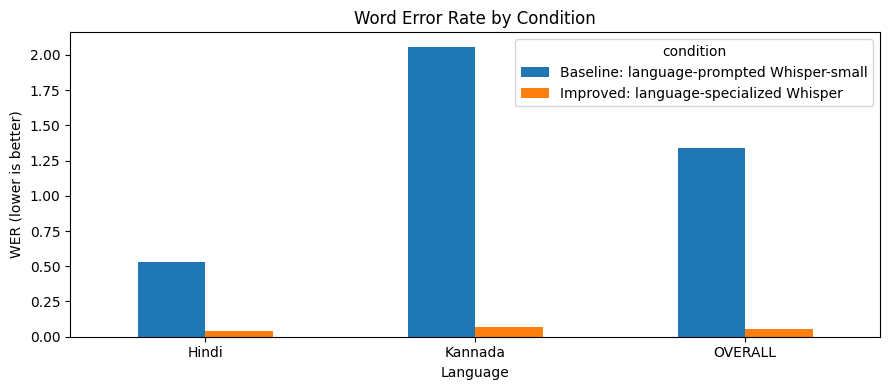

Saved: /content/task2_results_specialist/WER_comparison.png


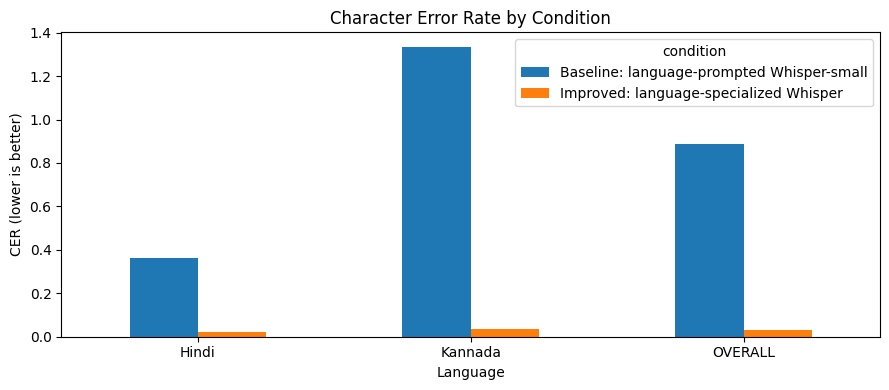

Saved: /content/task2_results_specialist/CER_comparison.png


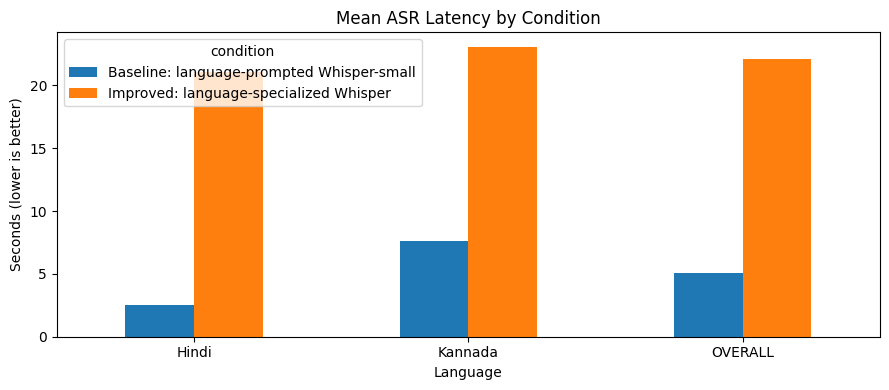

Saved: /content/task2_results_specialist/mean_latency_s_comparison.png


In [ ]:
import matplotlib.pyplot as plt
plot_df = metrics_df[metrics_df["language"].isin(["Hindi", "Kannada", "OVERALL"])].copy()

for metric, title, ylabel in [
    ("WER", "Word Error Rate by Condition", "WER (lower is better)"),
    ("CER", "Character Error Rate by Condition", "CER (lower is better)"),
    ("mean_latency_s", "Mean ASR Latency by Condition", "Seconds (lower is better)"),
]:
    pivot = plot_df.pivot(index="language", columns="condition", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9, 4))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Language")
    plt.xticks(rotation=0)
    plt.tight_layout()
    fig_path = OUTPUT_DIR / f"{metric}_comparison.png"
    plt.savefig(fig_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", fig_path)

## 9. Optional: run a speech-to-answer demo

This extra cell loads a compact instruction LLM. It is a demonstration, not a measured QA benchmark: FLEURS reference transcripts do not provide gold answers for arbitrary questions. Do not present generated answers as automatically verified. You can upload a short Hindi/Kannada audio question and the system will transcribe it, then answer the transcript in English.

In [ ]:
# Run this optional cell only after the ASR evaluation above has completed.
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,
)
if not torch.cuda.is_available():
    llm_model = llm_model.to("cpu")
print("Answer model ready:", LLM_ID)

Answer model ready: Qwen/Qwen2.5-1.5B-Instruct


In [ ]:
def transcribe_and_answer(audio_path, language="hindi"):
    # Transcribe an audio file and answer its spoken question in English.
    # language should be 'hindi' or 'kannada'.
    if language not in {"hindi", "kannada"}:
        raise ValueError("language must be 'hindi' or 'kannada'")

    transcript = asr(audio_path, generate_kwargs={"task": "transcribe", "language": language})["text"].strip()
    messages = [
        {"role": "system", "content": "You are a careful assistant. Answer the user's question in concise English. If the transcript is incomplete or unclear, say what is unclear rather than inventing details."},
        {"role": "user", "content": f"This is a speech-recognition transcript from a {language} recording. Answer the question if one is present. If it is not a question, briefly summarize its meaning.\n\nTranscript: {transcript}"},
    ]
    prompt = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tokenizer(prompt, return_tensors="pt")
    model_device = next(llm_model.parameters()).device
    inputs = {k: v.to(model_device) for k, v in inputs.items()}
    with torch.no_grad():
        output = llm_model.generate(**inputs, max_new_tokens=160, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = llm_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return {"transcript": transcript, "answer": answer}

# Example usage after uploading a file in the Colab file pane:
# result = transcribe_and_answer("/content/my_hindi_question.wav", language="hindi")
# print("Transcript:", result["transcript"])
# print("Answer:", result["answer"])

## 10. Proposed improvement: latency-aware turn-transition controller

This implements the simple decision policy proposed in Task 1. It uses speech activity, silence duration, a semantic-completeness confidence score, elapsed waiting time, and the remaining latency budget. The confidence value is an input to the policy—not something the ASR benchmark supplies automatically.

In [ ]:
from dataclasses import dataclass

@dataclass
class ControllerConfig:
    min_silence_ms: int = 300
    confidence_threshold: float = 0.75
    max_wait_ms: int = 1500

class LatencyAwareTurnController:
    def __init__(self, config=None):
        self.config = config or ControllerConfig()

    def decide(
        self,
        user_speech_active: bool,
        silence_ms: int,
        semantic_confidence: float,
        elapsed_wait_ms: int,
        remaining_budget_ms: int,
        assistant_speaking: bool = False,
        interruption_detected: bool = False,
    ) -> str:
        """Return one of: continue_listening, respond, continue_speaking, yield_turn."""
        if interruption_detected:
            return "yield_turn"
        if assistant_speaking:
            return "continue_speaking"
        if user_speech_active:
            return "continue_listening"
        enough_silence = silence_ms >= self.config.min_silence_ms
        confident_enough = semantic_confidence >= self.config.confidence_threshold
        budget_expired = remaining_budget_ms <= 0
        waited_too_long = elapsed_wait_ms >= self.config.max_wait_ms
        if enough_silence and confident_enough:
            return "respond"
        if budget_expired or waited_too_long:
            return "respond"
        return "continue_listening"

controller = LatencyAwareTurnController()

# Hand-designed unit tests: these verify policy branches, not real-world accuracy.
controller_cases = [
    {"case": "ongoing_user_speech", "user_speech_active": True, "silence_ms": 0, "semantic_confidence": 0.9, "elapsed_wait_ms": 300, "remaining_budget_ms": 1200, "assistant_speaking": False, "interruption_detected": False, "expected_action": "continue_listening"},
    {"case": "silence_and_high_confidence", "user_speech_active": False, "silence_ms": 450, "semantic_confidence": 0.91, "elapsed_wait_ms": 500, "remaining_budget_ms": 1000, "assistant_speaking": False, "interruption_detected": False, "expected_action": "respond"},
    {"case": "brief_pause", "user_speech_active": False, "silence_ms": 150, "semantic_confidence": 0.95, "elapsed_wait_ms": 500, "remaining_budget_ms": 1000, "assistant_speaking": False, "interruption_detected": False, "expected_action": "continue_listening"},
    {"case": "low_confidence_keep_waiting", "user_speech_active": False, "silence_ms": 400, "semantic_confidence": 0.42, "elapsed_wait_ms": 700, "remaining_budget_ms": 900, "assistant_speaking": False, "interruption_detected": False, "expected_action": "continue_listening"},
    {"case": "latency_budget_expired", "user_speech_active": False, "silence_ms": 200, "semantic_confidence": 0.40, "elapsed_wait_ms": 1400, "remaining_budget_ms": 0, "assistant_speaking": False, "interruption_detected": False, "expected_action": "respond"},
    {"case": "yield_to_interruption", "user_speech_active": True, "silence_ms": 0, "semantic_confidence": 0.8, "elapsed_wait_ms": 200, "remaining_budget_ms": 1000, "assistant_speaking": True, "interruption_detected": True, "expected_action": "yield_turn"},
    {"case": "assistant_keeps_speaking", "user_speech_active": False, "silence_ms": 0, "semantic_confidence": 0.5, "elapsed_wait_ms": 200, "remaining_budget_ms": 1000, "assistant_speaking": True, "interruption_detected": False, "expected_action": "continue_speaking"},
]

unit_rows = []
for case in controller_cases:
    case_inputs = {k: v for k, v in case.items() if k not in {"case", "expected_action"}}
    action = controller.decide(**case_inputs)
    unit_rows.append({"case": case["case"], "expected_action": case["expected_action"], "actual_action": action, "passed": action == case["expected_action"]})

controller_tests_df = pd.DataFrame(unit_rows)
CONTROLLER_TESTS_PATH = OUTPUT_DIR / "controller_unit_tests.csv"
controller_tests_df.to_csv(CONTROLLER_TESTS_PATH, index=False)
display(controller_tests_df)
print(f"Controller unit tests passed: {controller_tests_df['passed'].sum()}/{len(controller_tests_df)}")
print("Saved:", CONTROLLER_TESTS_PATH)


,case,expected_action,actual_action,passed
0,ongoing_user_speech,continue_listening,continue_listening,True
1,silence_and_high_confidence,respond,respond,True
2,brief_pause,continue_listening,continue_listening,True
3,low_confidence_keep_waiting,continue_listening,continue_listening,True
4,latency_budget_expired,respond,respond,True
5,yield_to_interruption,yield_turn,yield_turn,True
6,assistant_keeps_speaking,continue_speaking,continue_speaking,True


Controller unit tests passed: 7/7
Saved: /content/task2_results_specialist/controller_unit_tests.csv


## 11. Download the results

This creates a ZIP containing the sample-level CSV, summary metrics, and plots.

In [ ]:
import zipfile
ZIP_PATH = Path("/content/task2_results.zip")
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.iterdir():
        if path.is_file():
            zf.write(path, arcname=path.name)
print("Ready to download:", ZIP_PATH)

# In Google Colab, uncomment the next two lines to trigger a browser download:
from google.colab import files
files.download(str(ZIP_PATH))

Ready to download: /content/task2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>